# DQN 動能投資策略

本筆記本展示如何使用深度Q網路(DQN)學習動能投資策略。

## 核心概念
- **動能策略**：追漲殺跌 - 買入上升趨勢，賣出下跌趨勢
- **DQN**：深度強化學習算法，通過Q值逼近最優策略
- **目標**：自動學習何時買入、持有、賣出

## 1. 導入必要的庫

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque
import matplotlib.pyplot as plt
import warnings
import yfinance as yf # 導入yfinance
warnings.filterwarnings('ignore')

# 設定matplotlib中文字型，避免圖表中的中文標籤顯示為方框
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 設定隨機種子以確保可重複性
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

print("所有庫導入完成！")

所有庫導入完成！


## 2. 定義動能投資環境

In [2]:
class MomentumEnvironment:
    """動能投資策略環境"""

    def __init__(self, stock_data, initial_portfolio=100000,
                 transaction_cost=0.001, lookback_period=20,
                 reward_mode='momentum_shaped', dsr_eta=0.01):
        """
        初始化動能投資環境

        Args:
            stock_data: 股票價格數據 (Pandas Series 或 單列DataFrame)
            initial_portfolio: 初始投資組合價值
            transaction_cost: 交易成本比例
            lookback_period: 動能計算的回溯期間
            reward_mode: 獎勵函數版本
                - 'momentum_shaped': 原始版本，報酬 + 動能塑形 + 回撤懲罰
                - 'raw_return': 純報酬率，不做任何塑形（對照組）
                - 'differential_sharpe': 差分夏普比率 (Moody & Saffell, 1998)
                - 'differential_sortino': 差分Sortino比率（以下行風險取代變異數）
            dsr_eta: 差分Sharpe/Sortino的EWMA適應率
        """
        self.stock_data = stock_data
        self.initial_portfolio = initial_portfolio
        self.transaction_cost = transaction_cost
        self.lookback_period = lookback_period
        self.reward_mode = reward_mode
        self.dsr_eta = dsr_eta

        # 狀態維度：價格、5日動能、10日動能、20日動能、RSI、MACD、
        #          持倉比例、現金比例、收益率、波動率
        self.state_dim = 10
        # 動作維度：3個動作 - 賣出(-1), 持有(0), 買入(1)
        self.action_dim = 3

        self.reset()

    def reset(self):
        """重置環境"""
        self.current_step = self.lookback_period + 10  # 跳過初始期間以計算指標
        self.portfolio_value = self.initial_portfolio
        self.cash = self.initial_portfolio
        self.stock_position = 0  # 持有的股票數量
        self.entry_price = 0  # 買入價格
        self.max_portfolio_value = self.initial_portfolio

        # 差分Sharpe/Sortino的EWMA統計量
        self.dsr_A = 0.0   # 報酬率一階動差
        self.dsr_B = 0.0   # 報酬率二階動差
        self.sortino_A = 0.0   # 報酬率一階動差
        self.sortino_DD = 0.0  # 下行風險二階動差

        return self._get_state()

    def _calculate_momentum(self, period):
        """計算動能指標 (Momentum)"""
        if self.current_step < period:
            return 0

        current_price = self.stock_data.iloc[self.current_step].item()
        past_price = self.stock_data.iloc[self.current_step - period].item()

        return (current_price - past_price) / past_price if past_price > 0 else 0

    def _calculate_rsi(self, period=14):
        """計算相對強度指數 (RSI)"""
        if self.current_step < period:
            return 0.5

        prices = self.stock_data.iloc[self.current_step-period:self.current_step].values.flatten()

        if len(prices) < 2:
            return 0.5

        deltas = np.diff(prices)
        gains = np.where(deltas > 0, deltas, 0)
        losses = np.where(deltas < 0, -deltas, 0)

        avg_gain = np.mean(gains)
        avg_loss = np.mean(losses)

        if avg_loss == 0:
            return 1.0 if avg_gain > 0 else 0.5

        rs = avg_gain / avg_loss
        rsi = 1 - (1 / (1 + rs))

        return np.clip(rsi, 0, 1)

    def _calculate_macd(self):
        """計算MACD指標"""
        if self.current_step < 26:
            return 0

        prices = self.stock_data.iloc[self.current_step-26:self.current_step].values.flatten()

        # 簡化版MACD：快速EMA - 慢速EMA
        ema_12 = pd.Series(prices).ewm(span=12).mean().values[-1]
        ema_26 = pd.Series(prices).ewm(span=26).mean().values[-1]

        macd = (ema_12 - ema_26) / ema_26 if ema_26 > 0 else 0

        return np.clip(macd / 0.1, -1, 1)  # 正規化到[-1, 1]

    def _calculate_volatility(self, period=20):
        """計算波動率"""
        if self.current_step < period:
            return 0

        prices = self.stock_data.iloc[self.current_step-period:self.current_step].values.flatten()
        returns = np.diff(prices) / prices[:-1]

        return np.std(returns) * np.sqrt(252)

    def _get_state(self):
        """獲取當前狀態"""
        if self.current_step >= len(self.stock_data):
            return np.zeros(self.state_dim)

        current_price = self.stock_data.iloc[self.current_step].item()

        # 計算各項指標
        momentum_5 = self._calculate_momentum(5)
        momentum_10 = self._calculate_momentum(10)
        momentum_20 = self._calculate_momentum(20)
        rsi = self._calculate_rsi()
        macd = self._calculate_macd()
        volatility = self._calculate_volatility()

        # 計算當前P&L
        if self.stock_position > 0:
            unrealized_pnl = self.stock_position * (current_price - self.entry_price)
        else:
            unrealized_pnl = 0

        total_value = self.cash + self.stock_position * current_price
        return_rate = (total_value - self.initial_portfolio) / self.initial_portfolio

        # 持倉信息
        position_ratio = (self.stock_position * current_price) / total_value if total_value > 0 else 0
        cash_ratio = self.cash / total_value if total_value > 0 else 1

        # 狀態向量
        state = np.array([
            np.log(current_price / 100),  # 標準化價格
            momentum_5,                     # 5日動能
            momentum_10,                    # 10日動能
            momentum_20,                    # 20日動能
            rsi,                           # RSI
            macd,                          # MACD
            position_ratio,                # 持倉比例
            cash_ratio,                    # 現金比例
            np.clip(return_rate, -1, 1),  # 收益率
            volatility                     # 波動率
        ], dtype=np.float32)

        return state

    def _reward_raw_return(self, portfolio_return):
        """純報酬率獎勵，不做任何塑形，作為對照組(ablation baseline)"""
        return portfolio_return * 100

    def _reward_momentum_shaped(self, portfolio_return, action, new_portfolio_value):
        """原始版本：報酬 + 動能塑形 + 回撤懲罰"""
        reward = portfolio_return * 100  # 基本收益獎勵

        # 追漲時給予獎勵
        if action == 2:
            current_momentum = self._calculate_momentum(10)
            if current_momentum > 0.02:  # 2%以上動能
                reward += current_momentum * 50
            else:
                reward -= 2  # 在沒有動能時買入懲罰

        # 追殺時給予獎勵
        if action == 0:
            current_momentum = self._calculate_momentum(10)
            if current_momentum < -0.02:  # -2%以下動能
                reward += abs(current_momentum) * 50

        # 持有時基於趨勢給予獎勵
        if action == 1 and self.stock_position > 0:
            current_momentum = self._calculate_momentum(10)
            if current_momentum > 0:
                reward += abs(current_momentum) * 20
            else:
                reward -= abs(current_momentum) * 10

        # 最大回撤懲罰
        drawdown = (self.max_portfolio_value - new_portfolio_value) / self.max_portfolio_value
        if drawdown > 0.1:  # 超過10%回撤
            reward -= drawdown * 20

        return reward

    def _reward_differential_sharpe(self, portfolio_return):
        """差分夏普比率獎勵 (Moody & Saffell, 1998)

        以EWMA估計報酬率的一階動差A與二階動差B，用D_t = (B_{t-1}ΔA_t - 0.5*A_{t-1}ΔB_t) / (B_{t-1}-A_{t-1}^2)^1.5
        逼近夏普比率對時間的變化率，讓智能體在每一步就能得到風險調整後的即時獎勵訊號。
        """
        R = portfolio_return
        delta_A = R - self.dsr_A
        delta_B = R ** 2 - self.dsr_B

        denom = self.dsr_B - self.dsr_A ** 2
        if denom > 1e-8:
            dsr = (self.dsr_B * delta_A - 0.5 * self.dsr_A * delta_B) / (denom ** 1.5)
        else:
            dsr = 0.0

        # 更新EWMA統計量（供下一步使用）
        self.dsr_A += self.dsr_eta * delta_A
        self.dsr_B += self.dsr_eta * delta_B

        return dsr * 100

    def _reward_differential_sortino(self, portfolio_return):
        """差分Sortino比率獎勵

        延伸自差分夏普比率的推導方式，但將分母的變異數換成下行風險(只計算負報酬的平方)，
        使獎勵只懲罰虧損方向的波動，不懲罰上漲帶來的波動。
        """
        R = portfolio_return
        downside_sq = min(R, 0) ** 2

        delta_A = R - self.sortino_A
        delta_DD = downside_sq - self.sortino_DD

        if self.sortino_DD > 1e-8:
            dsor = (self.sortino_DD * delta_A - 0.5 * self.sortino_A * delta_DD) / (self.sortino_DD ** 1.5)
        else:
            dsor = 0.0

        self.sortino_A += self.dsr_eta * delta_A
        self.sortino_DD += self.dsr_eta * delta_DD

        return dsor * 100

    def step(self, action):
        """執行動作

        Action:
            0: 賣出所有持倉
            1: 保持現狀
            2: 買入（投入50%現金）
        """
        if self.current_step >= len(self.stock_data) - 1:
            return self._get_state(), 0, True, {}

        current_price = self.stock_data.iloc[self.current_step].item()

        # 記錄執行前的投資組合價值
        prev_portfolio_value = self.cash + self.stock_position * current_price

        # 執行動作
        if action == 0:  # 賣出
            if self.stock_position > 0:
                sell_value = self.stock_position * current_price
                transaction_cost_amount = sell_value * self.transaction_cost
                self.cash += sell_value - transaction_cost_amount
                self.stock_position = 0

        elif action == 2:  # 買入
            if self.stock_position == 0 and self.cash > 0:
                # 投入50%的現金
                invest_amount = self.cash * 0.5
                transaction_cost_amount = invest_amount * self.transaction_cost
                invest_amount -= transaction_cost_amount

                if invest_amount > 0:
                    self.stock_position = invest_amount / current_price
                    self.entry_price = current_price
                    self.cash -= invest_amount + transaction_cost_amount

        # 移動到下一時間步
        self.current_step += 1

        # 計算新的投資組合價值
        if self.current_step < len(self.stock_data):
            new_price = self.stock_data.iloc[self.current_step].item()
            new_portfolio_value = self.cash + self.stock_position * new_price
        else:
            new_portfolio_value = prev_portfolio_value

        # 計算報酬率
        portfolio_change = new_portfolio_value - prev_portfolio_value
        portfolio_return = portfolio_change / prev_portfolio_value if prev_portfolio_value > 0 else 0

        # 更新最大投資組合價值（用於計算最大回撤）
        self.max_portfolio_value = max(self.max_portfolio_value, new_portfolio_value)

        # 依reward_mode分派獎勵函數
        if self.reward_mode == 'raw_return':
            reward = self._reward_raw_return(portfolio_return)
        elif self.reward_mode == 'differential_sharpe':
            reward = self._reward_differential_sharpe(portfolio_return)
        elif self.reward_mode == 'differential_sortino':
            reward = self._reward_differential_sortino(portfolio_return)
        else:  # 'momentum_shaped'（預設，即原始版本）
            reward = self._reward_momentum_shaped(portfolio_return, action, new_portfolio_value)

        # 檢查是否結束
        done = (self.current_step >= len(self.stock_data) - 1 or
                new_portfolio_value <= self.initial_portfolio * 0.5)  # 虧損50%止損

        info = {
            'portfolio_value': new_portfolio_value,
            'stock_position': self.stock_position,
            'cash': self.cash,
            'action': action
        }

        return self._get_state(), reward, done, info

print("MomentumEnvironment 類定義完成！(支援可插拔獎勵函數: momentum_shaped / raw_return / differential_sharpe / differential_sortino)")

MomentumEnvironment 類定義完成！(支援可插拔獎勵函數: momentum_shaped / raw_return / differential_sharpe / differential_sortino)


## 3. 定義DQN神經網路

In [3]:
class DQNMomentumNetwork(nn.Module):
    """用於動能策略的DQN網路"""

    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super(DQNMomentumNetwork, self).__init__()

        # 特徵提取層
        self.features = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        # Q值輸出層
        self.q_values = nn.Linear(hidden_dim, action_dim)

    def forward(self, x):
        features = self.features(x)
        q_values = self.q_values(features)
        return q_values

print("DQNMomentumNetwork 類定義完成！")

DQNMomentumNetwork 類定義完成！


## 4. 定義DQN智能體

In [4]:
class MomentumDQNAgent:
    """動能投資DQN智能體"""

    def __init__(self, state_dim, action_dim, lr=0.001, gamma=0.95,
                 epsilon=1.0, epsilon_decay=0.998, epsilon_min=0.01,
                 memory_size=10000, batch_size=32):

        self.state_dim = state_dim
        self.action_dim = action_dim
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.batch_size = batch_size

        # 自動偵測GPU，若無CUDA則退回CPU
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 神經網路（搬到GPU/CPU）
        self.q_network = DQNMomentumNetwork(state_dim, action_dim).to(self.device)
        self.target_network = DQNMomentumNetwork(state_dim, action_dim).to(self.device)
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)

        # 經驗回放
        self.memory = deque(maxlen=memory_size)

        # 性能追蹤
        self.loss_history = []
        self.update_target_network()

    def update_target_network(self):
        """硬更新目標網路"""
        self.target_network.load_state_dict(self.q_network.state_dict())

    def remember(self, state, action, reward, next_state, done):
        """儲存經驗"""
        self.memory.append((state, action, reward, next_state, done))

    def act(self, state, training=True):
        """選擇動作"""
        if training and np.random.random() < self.epsilon:
            return np.random.randint(0, self.action_dim)

        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        # 單筆樣本推論需切換為eval模式，避免BatchNorm1d在batch size=1時報錯
        self.q_network.eval()
        with torch.no_grad():
            q_values = self.q_network(state_tensor)
        if training:
            self.q_network.train()
        return q_values.argmax(dim=1).item()

    def replay(self):
        """經驗回放學習"""
        if len(self.memory) < self.batch_size:
            return

        batch = random.sample(self.memory, self.batch_size)
        states = torch.FloatTensor([e[0] for e in batch]).to(self.device)
        actions = torch.LongTensor([e[1] for e in batch]).to(self.device)
        rewards = torch.FloatTensor([e[2] for e in batch]).to(self.device)
        next_states = torch.FloatTensor([e[3] for e in batch]).to(self.device)
        dones = torch.BoolTensor([e[4] for e in batch]).to(self.device)

        # 計算Q值
        q_values = self.q_network(states)
        current_q_values = q_values.gather(1, actions.unsqueeze(1)).squeeze(1)

        # 計算目標Q值
        with torch.no_grad():
            next_q_values = self.target_network(next_states).max(1)[0]
            target_q_values = rewards + (self.gamma * next_q_values * ~dones)

        # 計算損失
        loss = nn.MSELoss()(current_q_values, target_q_values)

        # 反向傳播
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.q_network.parameters(), 1.0)
        self.optimizer.step()

        self.loss_history.append(loss.item())

        # 衰減探索率
        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

print("MomentumDQNAgent 類定義完成！(自動偵測並使用GPU：", "cuda" if torch.cuda.is_available() else "cpu", ")")

MomentumDQNAgent 類定義完成！(自動偵測並使用GPU： cuda )


## 5. 定義輔助函數

In [5]:
def generate_stock_price_data(n_days=500, initial_price=100, volatility=0.2,
                              trend_strength=0.0, seed=42):
    """生成股票價格數據（幾何布朗運動 + 趨勢）

    Args:
        trend_strength: 趨勢強度 (-0.3 ~ 0.3)
    """
    np.random.seed(seed)

    dt = 1/252
    drift = 0.05 + trend_strength  # 年化漂移率

    prices = [initial_price]
    for i in range(n_days - 1):
        dW = np.random.normal(0, np.sqrt(dt))
        dS = prices[-1] * (drift * dt + volatility * dW)
        prices.append(max(prices[-1] + dS, 10))  # 價格不能低於10

    return pd.Series(prices)


def train_momentum_dqn(stock_data, episodes=500, verbose=True):
    """訓練動能DQN策略"""

    env = MomentumEnvironment(stock_data)
    agent = MomentumDQNAgent(env.state_dim, env.action_dim)

    scores = []
    portfolio_values = []
    actions_history = [[], [], []]  # 追蹤各動作的頻率

    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        episode_actions = [0, 0, 0]

        while True:
            action = agent.act(state)
            next_state, reward, done, info = env.step(action)

            agent.remember(state, action, reward, next_state, done)

            state = next_state
            total_reward += reward
            episode_actions[action] += 1

            if done:
                portfolio_values.append(info['portfolio_value'])
                break

        # 學習
        for _ in range(10):
            agent.replay()

        scores.append(total_reward)
        actions_history[0].append(episode_actions[0])  # 賣出
        actions_history[1].append(episode_actions[1])  # 持有
        actions_history[2].append(episode_actions[2])  # 買入

        # 每50個episode更新目標網路
        if (episode + 1) % 50 == 0:
            agent.update_target_network()

        if verbose and episode % 100 == 0:
            avg_score = np.mean(scores[-100:]) if len(scores) >= 100 else np.mean(scores)
            avg_portfolio = np.mean(portfolio_values[-100:]) if len(portfolio_values) >= 100 else portfolio_values[-1]

            print(f"Episode {episode}, Avg Reward: {avg_score:.2f}, "
                  f"Avg Portfolio: ${avg_portfolio:,.0f}, Epsilon: {agent.epsilon:.3f}")

    return agent, scores, portfolio_values, actions_history


def backtest_momentum_strategy(agent, stock_data, is_training=False):
    """回測動能策略"""
    env = MomentumEnvironment(stock_data)
    state = env.reset()

    portfolio_history = [env.initial_portfolio]
    action_history = []
    position_history = []

    while True:
        action = agent.act(state, training=is_training)
        state, reward, done, info = env.step(action)

        portfolio_history.append(info['portfolio_value'])
        action_history.append(action)
        position_history.append(info['stock_position'])

        if done:
            break

    return {
        'portfolio_history': np.array(portfolio_history),
        'action_history': np.array(action_history),
        'position_history': np.array(position_history)
    }


def classic_momentum_strategy(stock_data, initial_portfolio=100000, transaction_cost=0.001,
                               momentum_period=10, lookback_period=20, start_offset=10):
    """傳統(非學習)時間序列動能法則：N日動能>0則100%做多，否則100%空手持現金

    這是財務文獻中標準的time-series momentum規則(如Moskowitz, Ooi & Pedersen, 2012)，
    完全不透過強化學習，用來檢驗「動能訊號本身是否具有可獲利性」，
    與DQN智能體的表現互為補充證據。

    Args:
        start_offset: 與MomentumEnvironment對齊的起始位移，
                      使回測起點與DQN/買入持有一致(lookback_period + start_offset)
    """
    start_step = lookback_period + start_offset
    cash = initial_portfolio
    position = 0.0
    portfolio_history = [initial_portfolio]

    for t in range(start_step, len(stock_data) - 1):
        current_price = stock_data.iloc[t].item()
        past_price = stock_data.iloc[t - momentum_period].item()
        momentum = (current_price - past_price) / past_price if past_price > 0 else 0

        want_long = momentum > 0

        if want_long and position == 0 and cash > 0:
            # 100%資金做多(標準動能法則的慣例，非DQN的50%進場)
            invest_amount = cash * (1 - transaction_cost)
            position = invest_amount / current_price
            cash = 0.0
        elif (not want_long) and position > 0:
            cash = position * current_price * (1 - transaction_cost)
            position = 0.0

        portfolio_value = cash + position * current_price
        portfolio_history.append(portfolio_value)

    return np.array(portfolio_history)


def calculate_drawdown_durations(cumulative):
    """計算回撤持續期間(天數)：從創新高之後到重新回到前高為止的天數

    Args:
        cumulative: 累積淨值序列(例如 np.cumprod(1+returns))
    Returns:
        (每一段回撤的天數列表)
    """
    running_max = np.maximum.accumulate(cumulative)
    in_drawdown = cumulative < running_max

    durations = []
    current_duration = 0
    for flag in in_drawdown:
        if flag:
            current_duration += 1
        else:
            if current_duration > 0:
                durations.append(current_duration)
            current_duration = 0
    if current_duration > 0:  # 期末仍處於回撤中，計入尚未恢復的回撤期
        durations.append(current_duration)

    return durations


def calculate_metrics(portfolio_history):
    """計算策略性能指標"""
    returns = np.diff(portfolio_history) / portfolio_history[:-1]

    # 年化收益率
    total_return = (portfolio_history[-1] - portfolio_history[0]) / portfolio_history[0]
    annual_return = (1 + total_return) ** (252 / len(returns)) - 1

    # 年化波動率
    annual_volatility = np.std(returns) * np.sqrt(252)

    # 夏普比率 (假設無風險利率2%)
    sharpe_ratio = (annual_return - 0.02) / annual_volatility if annual_volatility > 0 else 0

    # 最大回撤
    cumulative = np.cumprod(1 + returns)
    running_max = np.maximum.accumulate(cumulative)
    drawdown = (cumulative - running_max) / running_max
    max_drawdown = np.min(drawdown)

    # 回撤持續期間
    durations = calculate_drawdown_durations(cumulative)
    max_drawdown_duration = max(durations) if durations else 0
    avg_drawdown_duration = float(np.mean(durations)) if durations else 0.0

    # 獲勝率
    win_rate = np.sum(returns > 0) / len(returns)

    return {
        'total_return': total_return,
        'annual_return': annual_return,
        'annual_volatility': annual_volatility,
        'sharpe_ratio': sharpe_ratio,
        'max_drawdown': max_drawdown,
        'max_drawdown_duration': max_drawdown_duration,
        'avg_drawdown_duration': avg_drawdown_duration,
        'win_rate': win_rate
    }

print("所有輔助函數定義完成！(新增: classic_momentum_strategy, 回撤持續期間計算)")

所有輔助函數定義完成！(新增: classic_momentum_strategy, 回撤持續期間計算)


## 6. 生成股票數據

從yfinance下載元大台灣50(0050)股價數據...


[*********************100%***********************]  1 of 1 completed

資料總長度: 1215 天（近5年）
訓練數據: 1093 天
測試數據: 122 天（與訓練集不重疊）
股價範圍: $21.75 - $110.48


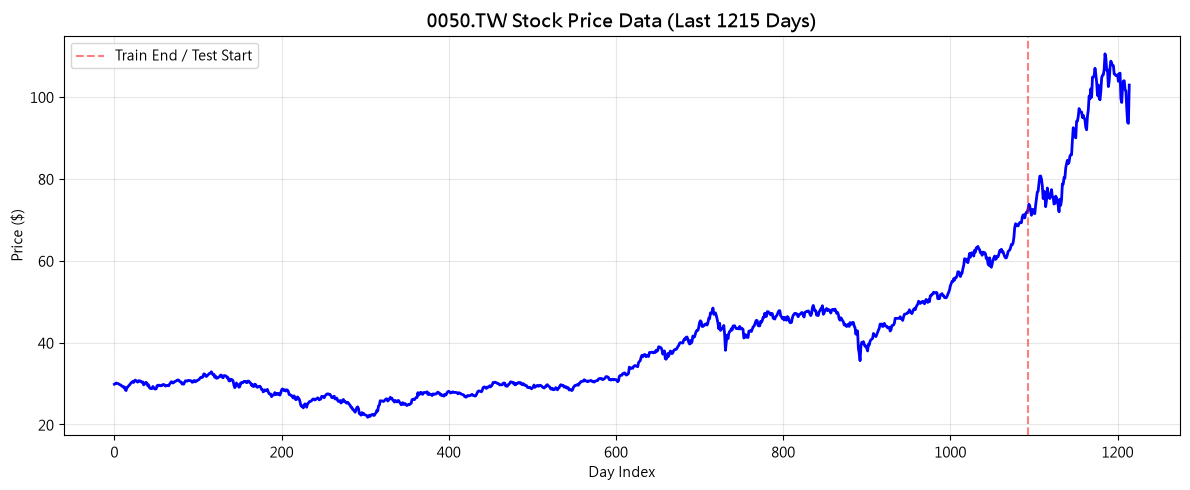

In [6]:
print("從yfinance下載元大台灣50(0050)股價數據...")
# 下載元大台灣50 ETF (0050.TW) 股票數據，取近5年資料
ticker = "0050.TW"
data = yf.download(ticker, period="5y")

# 提取收盤價，並確保為Pandas Series
stock_data = data['Close'].dropna()

# 檢查是否下載到數據
if stock_data.empty:
    print(f"錯誤：未能下載 {ticker} 的股票數據。請檢查股票代碼或網路連接。")
    # 為了避免後續錯誤，將train_data和test_data設置為空Series
    train_data = pd.Series()
    test_data = pd.Series()
else:
    # 重置索引，使其從0開始，便於環境中使用iloc
    stock_data = stock_data.reset_index(drop=True)

    # 分割訓練和測試數據（不重疊，確保測試集為真正的樣本外資料）
    train_split_idx = int(len(stock_data) * 0.90)  # 前90%用於訓練
    test_start_idx = train_split_idx                # 測試集從訓練集結束處開始，不重疊

    train_data = stock_data.iloc[:train_split_idx]
    test_data = stock_data.iloc[test_start_idx:]

    print(f"資料總長度: {len(stock_data)} 天（近5年）")
    print(f"訓練數據: {len(train_data)} 天")
    print(f"測試數據: {len(test_data)} 天（與訓練集不重疊）")
    # 修改此行以正確格式化Series的單一值
    print(f"股價範圍: ${stock_data.min().item():.2f} - ${stock_data.max().item():.2f}")

    # 繪製股票價格
    plt.figure(figsize=(12, 5))
    plt.plot(stock_data.values, linewidth=2, color='blue')
    plt.axvline(x=train_split_idx, color='red', linestyle='--', alpha=0.5, label='Train End / Test Start')
    plt.title(f'{ticker} Stock Price Data (Last {len(stock_data)} Days)', fontsize=14, fontweight='bold')
    plt.xlabel('Day Index')
    plt.ylabel('Price ($)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 7. 訓練DQN智能體

這可能需要幾分鐘時間...

In [7]:
print("訓練DQN動能策略...")
print("=" * 60)

agent, scores, portfolio_values, actions_history = train_momentum_dqn(
    train_data, episodes=500, verbose=True
)

print("\n訓練完成！")

訓練DQN動能策略...


Episode 0, Avg Reward: 134.52, Avg Portfolio: $113,568, Epsilon: 0.980


Episode 100, Avg Reward: 677.07, Avg Portfolio: $129,386, Epsilon: 0.132


Episode 200, Avg Reward: 1330.54, Avg Portfolio: $154,638, Epsilon: 0.018


Episode 300, Avg Reward: 1383.58, Avg Portfolio: $153,828, Epsilon: 0.010


Episode 400, Avg Reward: 1347.21, Avg Portfolio: $153,405, Epsilon: 0.010



訓練完成！


## 8. 進行回測

In [8]:
print("在訓練數據上進行回測...")
train_results = backtest_momentum_strategy(agent, train_data, is_training=False)

print("在測試數據上進行回測...")
test_results = backtest_momentum_strategy(agent, test_data, is_training=False)

print("計算基準策略（買入持有）...")
env_buy_hold = MomentumEnvironment(test_data)
buy_hold_portfolio = [env_buy_hold.initial_portfolio]
state = env_buy_hold.reset()

while True:
    state, reward, done, info = env_buy_hold.step(2)  # 一直買入
    buy_hold_portfolio.append(info['portfolio_value'])
    if done:
        break

buy_hold_portfolio = np.array(buy_hold_portfolio)
print("\n回測完成！")

在訓練數據上進行回測...


在測試數據上進行回測...
計算基準策略（買入持有）...

回測完成！


## 9. 計算性能指標

In [9]:
print("\n" + "=" * 60)
print("性能指標對比")
print("=" * 60)

dqn_metrics = calculate_metrics(test_results['portfolio_history'])
buy_hold_metrics = calculate_metrics(buy_hold_portfolio)

print("\nDQN動能策略：")
print(f"  總收益:       {dqn_metrics['total_return']:>8.2%}")
print(f"  年化收益:     {dqn_metrics['annual_return']:>8.2%}")
print(f"  年化波動:     {dqn_metrics['annual_volatility']:>8.2%}")
print(f"  夏普比:       {dqn_metrics['sharpe_ratio']:>8.2f}")
print(f"  最大回撤:     {dqn_metrics['max_drawdown']:>8.2%}")
print(f"  獲勝率:       {dqn_metrics['win_rate']:>8.2%}")

print("\n買入持有策略：")
print(f"  總收益:       {buy_hold_metrics['total_return']:>8.2%}")
print(f"  年化收益:     {buy_hold_metrics['annual_return']:>8.2%}")
print(f"  年化波動:     {buy_hold_metrics['annual_volatility']:>8.2%}")
print(f"  夏普比:       {buy_hold_metrics['sharpe_ratio']:>8.2f}")
print(f"  最大回撤:     {buy_hold_metrics['max_drawdown']:>8.2%}")
print(f"  獲勝率:       {buy_hold_metrics['win_rate']:>8.2%}")

print("\n性能改善：")
print(f"  收益改善:     {(dqn_metrics['total_return'] - buy_hold_metrics['total_return']):>8.2%}")
print(f"  夏普比改善:   {(dqn_metrics['sharpe_ratio'] - buy_hold_metrics['sharpe_ratio']):>8.2f}")
print(f"  最大回撤改善: {(dqn_metrics['max_drawdown'] - buy_hold_metrics['max_drawdown']):>8.2%}")
print("=" * 60)


性能指標對比

DQN動能策略：
  總收益:          6.84%
  年化收益:       20.10%
  年化波動:       12.03%
  夏普比:           1.50
  最大回撤:       -6.57%
  獲勝率:         25.27%

買入持有策略：
  總收益:         18.10%
  年化收益:       58.51%
  年化波動:       20.78%
  夏普比:           2.72
  最大回撤:       -9.13%
  獲勝率:         48.35%

性能改善：
  收益改善:      -11.26%
  夏普比改善:      -1.22
  最大回撤改善:    2.56%


## 10. 可視化結果

繪製結果圖表...



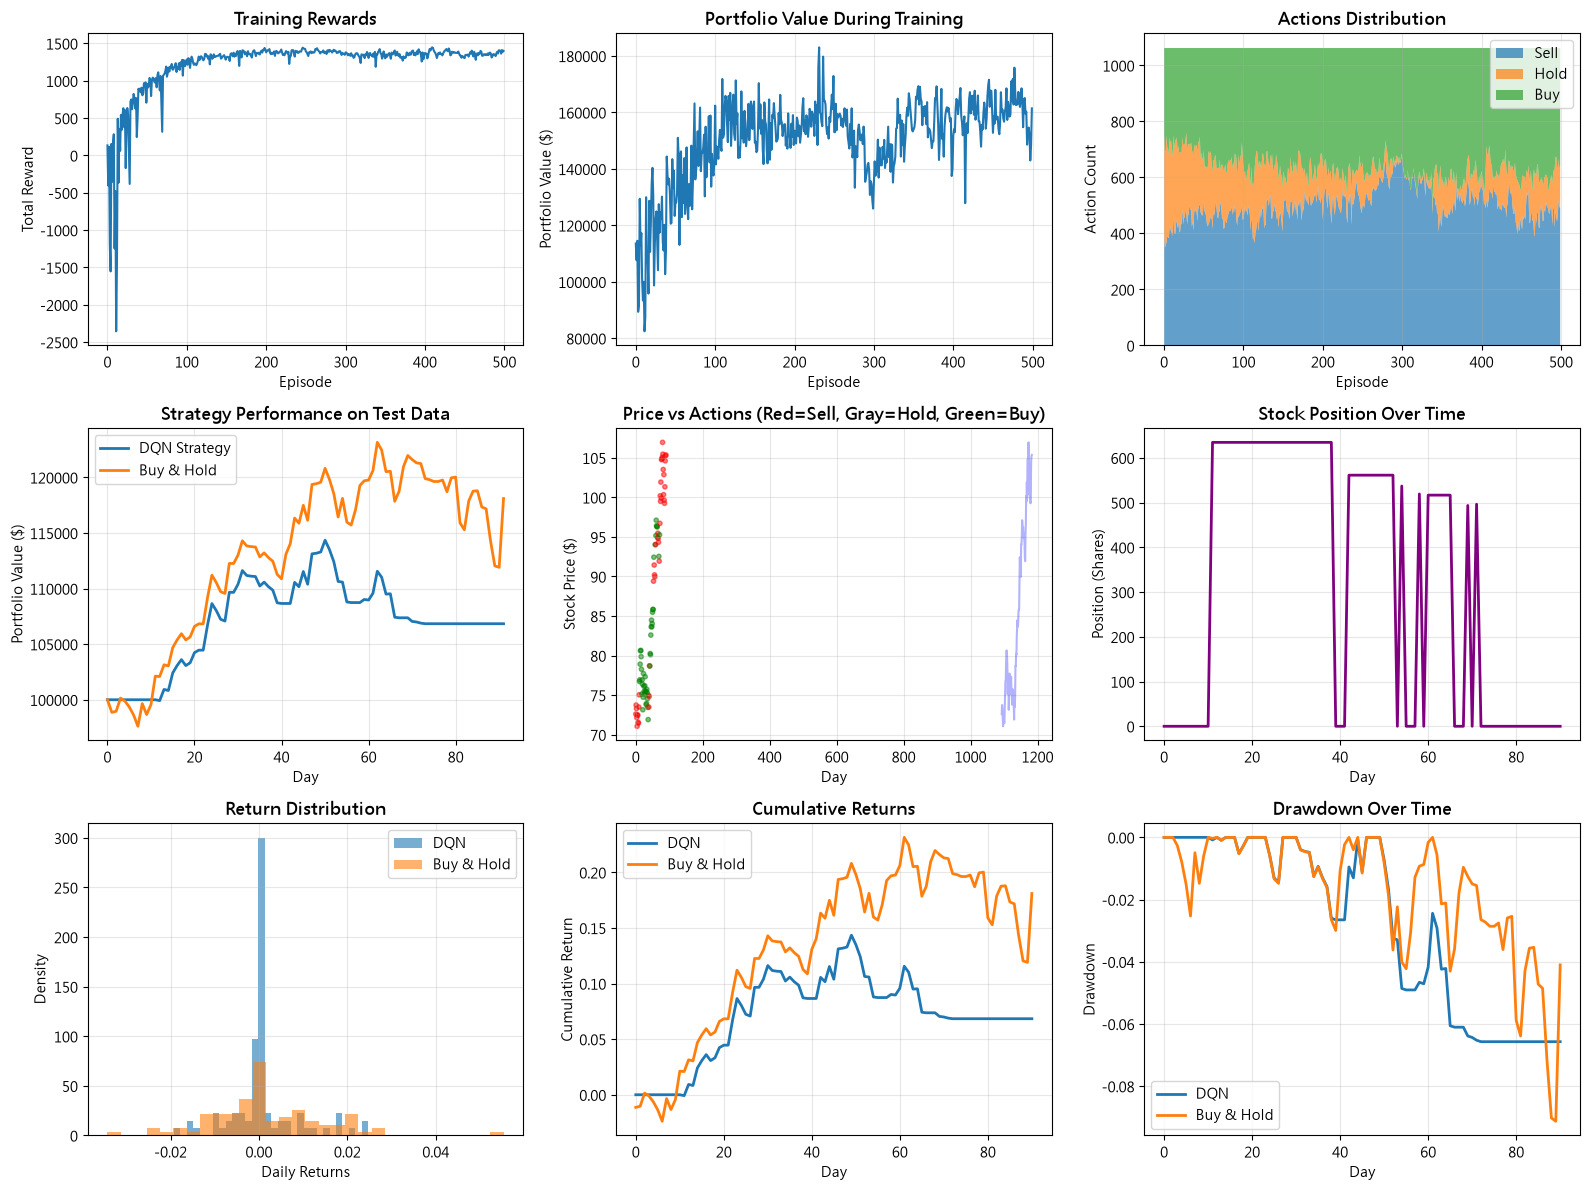


所有圖表已顯示！


In [10]:
print("繪製結果圖表...\n")

plt.figure(figsize=(16, 12))

# 訓練過程
plt.subplot(3, 3, 1)
plt.plot(scores, linewidth=1.5)
plt.title('Training Rewards', fontsize=12, fontweight='bold')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.grid(True, alpha=0.3)

# 投資組合價值
plt.subplot(3, 3, 2)
plt.plot(portfolio_values, linewidth=1.5)
plt.title('Portfolio Value During Training', fontsize=12, fontweight='bold')
plt.xlabel('Episode')
plt.ylabel('Portfolio Value ($)')
plt.grid(True, alpha=0.3)

# 動作分佈
plt.subplot(3, 3, 3)
episodes_range = range(len(actions_history[0]))
plt.stackplot(episodes_range, actions_history[0], actions_history[1],
             actions_history[2], labels=['Sell', 'Hold', 'Buy'], alpha=0.7)
plt.title('Actions Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Episode')
plt.ylabel('Action Count')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

# 測試數據回測結果
plt.subplot(3, 3, 4)
plt.plot(test_results['portfolio_history'], label='DQN Strategy', linewidth=2)
plt.plot(buy_hold_portfolio, label='Buy & Hold', linewidth=2)
plt.title('Strategy Performance on Test Data', fontsize=12, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Portfolio Value ($)')
plt.legend()
plt.grid(True, alpha=0.3)

# 股票價格 vs 動作
plt.subplot(3, 3, 5)
test_data_plot = test_data.iloc[:len(test_results['action_history'])]
colors = ['red' if a == 0 else 'gray' if a == 1 else 'green'
          for a in test_results['action_history']]
plt.scatter(range(len(test_results['action_history'])), test_data_plot,
           c=colors, alpha=0.5, s=10)
plt.plot(test_data_plot, alpha=0.3, color='blue')
plt.title('Price vs Actions (Red=Sell, Gray=Hold, Green=Buy)',
         fontsize=12, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Stock Price ($)')
plt.grid(True, alpha=0.3)

# 持倉變化
plt.subplot(3, 3, 6)
plt.plot(test_results['position_history'], linewidth=2, color='purple')
plt.title('Stock Position Over Time', fontsize=12, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Position (Shares)')
plt.grid(True, alpha=0.3)

# 收益率分佈
plt.subplot(3, 3, 7)
dqn_returns = np.diff(test_results['portfolio_history']) / test_results['portfolio_history'][:-1]
bh_returns = np.diff(buy_hold_portfolio) / buy_hold_portfolio[:-1]
plt.hist(dqn_returns, bins=30, alpha=0.6, label='DQN', density=True)
plt.hist(bh_returns, bins=30, alpha=0.6, label='Buy & Hold', density=True)
plt.title('Return Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Daily Returns')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)

# 累積收益
plt.subplot(3, 3, 8)
dqn_cum_return = np.cumprod(1 + dqn_returns) - 1
bh_cum_return = np.cumprod(1 + bh_returns) - 1
plt.plot(dqn_cum_return, label='DQN', linewidth=2)
plt.plot(bh_cum_return, label='Buy & Hold', linewidth=2)
plt.title('Cumulative Returns', fontsize=12, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True, alpha=0.3)

# 回撤分析
plt.subplot(3, 3, 9)
dqn_cumulative = np.cumprod(1 + dqn_returns)
dqn_running_max = np.maximum.accumulate(dqn_cumulative)
dqn_drawdown = (dqn_cumulative - dqn_running_max) / dqn_running_max

bh_cumulative = np.cumprod(1 + bh_returns)
bh_running_max = np.maximum.accumulate(bh_cumulative)
bh_drawdown = (bh_cumulative - bh_running_max) / bh_running_max

plt.plot(dqn_drawdown, label='DQN', linewidth=2)
plt.plot(bh_drawdown, label='Buy & Hold', linewidth=2)
plt.title('Drawdown Over Time', fontsize=12, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Drawdown')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n所有圖表已顯示！")

## 11. 策略分析總結

In [11]:
print("\n" + "=" * 70)
print("DQN動能投資策略分析總結")
print("=" * 70)

print("\n【策略特點】")
print("  ✓ 自動學習追漲殺跌的最優時機")
print("  ✓ 基於多種技術指標（動能、RSI、MACD）做出決策")
print("  ✓ 動態調整持倉比例和交易頻率")
print("  ✓ 考慮交易成本和回撤控制")

print("\n【交易信號統計】")
total_actions = len(test_results['action_history'])
n_sell = np.sum(test_results['action_history'] == 0)
n_hold = np.sum(test_results['action_history'] == 1)
n_buy = np.sum(test_results['action_history'] == 2)

print(f"  賣出 (Sell):  {n_sell:3d} 次 ({n_sell/total_actions:5.1%})")
print(f"  持有 (Hold):  {n_hold:3d} 次 ({n_hold/total_actions:5.1%})")
print(f"  買入 (Buy):   {n_buy:3d} 次 ({n_buy/total_actions:5.1%})")

print("\n【風險指標對比】")
print(f"  指標           DQN策略      買入持有      優勢")
print(f"  ─" * 35)
print(f"  夏普比    {dqn_metrics['sharpe_ratio']:>7.2f}      {buy_hold_metrics['sharpe_ratio']:>7.2f}      {'DQN' if dqn_metrics['sharpe_ratio'] > buy_hold_metrics['sharpe_ratio'] else 'B&H'}")
print(f"  最大回撤  {dqn_metrics['max_drawdown']:>7.1%}     {buy_hold_metrics['max_drawdown']:>7.1%}     {'DQN' if dqn_metrics['max_drawdown'] > buy_hold_metrics['max_drawdown'] else 'B&H'}")
print(f"  年化波動  {dqn_metrics['annual_volatility']:>7.1%}     {buy_hold_metrics['annual_volatility']:>7.1%}     {'DQN' if dqn_metrics['annual_volatility'] < buy_hold_metrics['annual_volatility'] else 'B&H'}")
print(f"  獲勝率    {dqn_metrics['win_rate']:>7.1%}     {buy_hold_metrics['win_rate']:>7.1%}     {'DQN' if dqn_metrics['win_rate'] > buy_hold_metrics['win_rate'] else 'B&H'}")

print("\n【改進方向】")
print("  1. 增加更多特徵（成交量、開盤價、收盤價等）")
print("  2. 使用雙DQN或優先經驗回放改進算法")
print("  3. 加入風險管理模塊（止損、止盈）")
print("  4. 進行超參數優化（學習率、折扣因子等）")
print("  5. 在真實市場數據上驗證")
print("  6. 多資產組合優化")

print("\n" + "=" * 70)


DQN動能投資策略分析總結

【策略特點】
  ✓ 自動學習追漲殺跌的最優時機
  ✓ 基於多種技術指標（動能、RSI、MACD）做出決策
  ✓ 動態調整持倉比例和交易頻率
  ✓ 考慮交易成本和回撤控制

【交易信號統計】
  賣出 (Sell):   42 次 (46.2%)
  持有 (Hold):    0 次 ( 0.0%)
  買入 (Buy):    49 次 (53.8%)

【風險指標對比】
  指標           DQN策略      買入持有      優勢
  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─
  夏普比       1.50         2.72      B&H
  最大回撤    -6.6%       -9.1%     DQN
  年化波動    12.0%       20.8%     DQN
  獲勝率      25.3%       48.4%     B&H

【改進方向】
  1. 增加更多特徵（成交量、開盤價、收盤價等）
  2. 使用雙DQN或優先經驗回放改進算法
  3. 加入風險管理模塊（止損、止盈）
  4. 進行超參數優化（學習率、折扣因子等）
  5. 在真實市場數據上驗證
  6. 多資產組合優化



## 12. 獎勵函數比較實驗

聚焦於一個更聚焦、統計檢定力更強的問題：**動能塑形獎勵是否確實比無塑形的原始報酬帶來更好的DQN訓練成效？**

| 獎勵函數 | 設計理念 |
|---|---|
| `raw_return` | 純報酬率，無任何塑形（對照組） |
| `momentum_shaped` | 報酬 + 動能加成/懲罰 + 回撤懲罰 |

**實驗設計**：每種獎勵函數各用 10 個不同隨機種子（42–51）各訓練一次（500輪），在同一組**不重疊**的測試集上回測（訓練/測試集為前90%/後10%不重疊切分，且改用近5年的0050資料），並對關鍵指標（含總報酬、夏普比、最大回撤、最大/平均回撤持續期間）做Mann-Whitney U檢定。

**設計說明**：這裡刻意排除了差分夏普/Sortino比率兩種獎勵函數。原因是它們的獎勵量級不穩定（分母趨近0時會爆衝），與固定的學習率、梯度裁剪門檻搭配時會產生混淆變數，使得「獎勵設計優劣」與「獎勵量級和超參數的交互作用」難以區分。`raw_return`與`momentum_shaped`兩者獎勵量級相近，是較乾淨的對照組合。

**買入持有**與**傳統時間序列動能法則**在此僅作為固定參考基準，用來提供績效與風險指標的外部對照，不用於論證市場是否存在動能效應。

In [12]:
REWARD_MODES = {
    'raw_return': '原始報酬(無塑形)',
    'momentum_shaped': '動能塑形(原始版本)',
}

SEEDS = [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]


def train_and_evaluate(train_data, test_data, reward_mode, seed, episodes=500):
    """用指定的獎勵函數與隨機種子訓練一次DQN，並回傳測試集回測結果"""
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)

    env = MomentumEnvironment(train_data, reward_mode=reward_mode)
    agent = MomentumDQNAgent(env.state_dim, env.action_dim)

    for episode in range(episodes):
        state = env.reset()
        while True:
            action = agent.act(state)
            next_state, reward, done, info = env.step(action)
            agent.remember(state, action, reward, next_state, done)
            state = next_state
            if done:
                break

        for _ in range(10):
            agent.replay()

        if (episode + 1) % 50 == 0:
            agent.update_target_network()

    test_results = backtest_momentum_strategy(agent, test_data, is_training=False)
    metrics = calculate_metrics(test_results['portfolio_history'])
    metrics['reward_mode'] = reward_mode
    metrics['seed'] = seed
    metrics['portfolio_history'] = test_results['portfolio_history']

    return metrics

print("獎勵函數比較實驗函數定義完成！")

獎勵函數比較實驗函數定義完成！


### 固定規則基準（買入持有、傳統動能法則）

額外加入兩個不經學習、完全依固定規則執行的基準策略，作為DQN兩種獎勵函數的外部參考點：
- **買入持有**：測試期一開始即進場並持有至結束
- **傳統時間序列動能法則**：單純依10日動能訊號進出（動能>0持有多頭部位，否則空手，100%資金進出）

這兩者純粹用來提供績效／風險的參考座標，說明DQN策略相對於「什麼都不做」與「最簡單的動能規則」的位置，不作為市場動能效應是否存在的證據。

In [13]:
print("計算固定規則基準（買入持有、傳統動能法則）...")

classic_momentum_portfolio = classic_momentum_strategy(test_data)
classic_momentum_metrics = calculate_metrics(classic_momentum_portfolio)

print("\n傳統動能法則 vs 買入持有（僅供參考，兩者皆為固定規則、無隨機種子重複）：")
print(f"  {'指標':<12s}  {'動能法則':>12s}  {'買入持有':>12s}")
print(f"  {'總報酬':<12s}  {classic_momentum_metrics['total_return']:>11.2%}  {buy_hold_metrics['total_return']:>11.2%}")
print(f"  {'夏普比':<12s}  {classic_momentum_metrics['sharpe_ratio']:>12.2f}  {buy_hold_metrics['sharpe_ratio']:>12.2f}")
print(f"  {'最大回撤':<12s}  {classic_momentum_metrics['max_drawdown']:>11.2%}  {buy_hold_metrics['max_drawdown']:>11.2%}")
print(f"  {'最大回撤持續(天)':<12s}  {classic_momentum_metrics['max_drawdown_duration']:>12.0f}  {buy_hold_metrics['max_drawdown_duration']:>12.0f}")
print(f"  {'平均回撤持續(天)':<12s}  {classic_momentum_metrics['avg_drawdown_duration']:>12.1f}  {buy_hold_metrics['avg_drawdown_duration']:>12.1f}")

計算固定規則基準（買入持有、傳統動能法則）...

傳統動能法則 vs 買入持有（僅供參考，兩者皆為固定規則、無隨機種子重複）：
  指標                    動能法則          買入持有
  總報酬                19.48%       18.10%
  夏普比                   2.52          2.72
  最大回撤              -10.75%       -9.13%
  最大回撤持續(天)               40            29
  平均回撤持續(天)              7.9           6.7


### 執行實驗

2種獎勵函數 × 10個種子 = 20次獨立訓練，每次500輪，且訓練集擴大為近5年資料(約90%)，預期單次訓練時間會明顯拉長。為避免執行途中意外中斷導致進度全失，此處加入checkpoint機制：每完成一次訓練就立即存檔，若中斷後重新執行，會自動跳過已完成的(獎勵函數,種子)組合。

In [14]:
import time
import pickle
import os

CHECKPOINT_PATH = r'C:\Users\test\AppData\Local\Temp\claude\C--Users-test-Claude-Code\a95853c8-01ab-4c33-881f-e27cc79ee35a\scratchpad\reward_comparison_checkpoint_0050_5y.pkl'

if os.path.exists(CHECKPOINT_PATH):
    with open(CHECKPOINT_PATH, 'rb') as f:
        reward_comparison_results = pickle.load(f)
    print(f"從checkpoint恢復，已有 {len(reward_comparison_results)} 筆結果")

    # 若calculate_metrics新增了欄位(例如回撤持續期間)，用已存的portfolio_history重新計算補上，
    # 不需要重新訓練，節省大量時間
    _needs_backfill = any(
        'max_drawdown_duration' not in m or 'avg_drawdown_duration' not in m
        for m in reward_comparison_results
    )
    if _needs_backfill:
        print("偵測到新的指標欄位，正在用既有的portfolio_history補算(不需重新訓練)...")
        for m in reward_comparison_results:
            new_metrics = calculate_metrics(m['portfolio_history'])
            m.update(new_metrics)
        with open(CHECKPOINT_PATH, 'wb') as f:
            pickle.dump(reward_comparison_results, f)
        print("補算完成並已更新checkpoint。")
else:
    reward_comparison_results = []

completed = {(m['reward_mode'], m['seed']) for m in reward_comparison_results}
_start = time.time()

for reward_mode in REWARD_MODES:
    for seed in SEEDS:
        if (reward_mode, seed) in completed:
            print(f"[{REWARD_MODES[reward_mode]:>14s}] seed={seed}  已在checkpoint中，跳過")
            continue

        _t0 = time.time()
        m = train_and_evaluate(train_data, test_data, reward_mode, seed, episodes=500)
        reward_comparison_results.append(m)

        with open(CHECKPOINT_PATH, 'wb') as f:
            pickle.dump(reward_comparison_results, f)

        print(f"[{REWARD_MODES[reward_mode]:>14s}] seed={seed}  "
              f"總報酬:{m['total_return']:>7.2%}  夏普比:{m['sharpe_ratio']:>6.2f}  "
              f"最大回撤:{m['max_drawdown']:>7.2%}  ({time.time()-_t0:.0f}s)")

print(f"\n全部完成，總耗時 {(time.time()-_start)/60:.1f} 分鐘")

從checkpoint恢復，已有 20 筆結果
[     原始報酬(無塑形)] seed=42  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=43  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=44  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=45  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=46  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=47  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=48  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=49  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=50  已在checkpoint中，跳過
[     原始報酬(無塑形)] seed=51  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=42  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=43  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=44  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=45  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=46  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=47  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=48  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=49  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=50  已在checkpoint中，跳過
[    動能塑形(原始版本)] seed=51  已在checkpoint中，跳過

全部完成，總耗時 0.0 分鐘


In [15]:
reward_comparison_df = pd.DataFrame([
    {k: v for k, v in m.items() if k != 'portfolio_history'}
    for m in reward_comparison_results
])

metric_cols = ['total_return', 'annual_return', 'annual_volatility',
               'sharpe_ratio', 'max_drawdown', 'max_drawdown_duration',
               'avg_drawdown_duration', 'win_rate']

summary = reward_comparison_df.groupby('reward_mode')[metric_cols].agg(['mean', 'std'])
summary = summary.reindex(REWARD_MODES.keys())

pct_cols = ('total_return', 'annual_return', 'annual_volatility', 'max_drawdown', 'win_rate')

print("=" * 80)
print("獎勵函數比較（10個種子的平均值 ± 標準差）")
print("=" * 80)
for reward_mode in REWARD_MODES:
    print(f"\n【{REWARD_MODES[reward_mode]}】 ({reward_mode})")
    for col in metric_cols:
        mean = summary.loc[reward_mode, (col, 'mean')]
        std = summary.loc[reward_mode, (col, 'std')]
        if col in pct_cols:
            print(f"  {col:<22s}: {mean:>8.2%} ± {std:.2%}")
        else:
            print(f"  {col:<22s}: {mean:>8.2f} ± {std:.2f}")

print("\n" + "=" * 80)
print("固定基準策略（不經隨機種子重複，僅供參考）：")
print(f"  買入持有：       總報酬 {buy_hold_metrics['total_return']:.2%}  夏普比 {buy_hold_metrics['sharpe_ratio']:.2f}  "
      f"最大回撤 {buy_hold_metrics['max_drawdown']:.2%}  最大回撤持續 {buy_hold_metrics['max_drawdown_duration']:.0f}天  "
      f"平均回撤持續 {buy_hold_metrics['avg_drawdown_duration']:.1f}天")
print(f"  傳統動能法則：   總報酬 {classic_momentum_metrics['total_return']:.2%}  夏普比 {classic_momentum_metrics['sharpe_ratio']:.2f}  "
      f"最大回撤 {classic_momentum_metrics['max_drawdown']:.2%}  最大回撤持續 {classic_momentum_metrics['max_drawdown_duration']:.0f}天  "
      f"平均回撤持續 {classic_momentum_metrics['avg_drawdown_duration']:.1f}天")
print("=" * 80)

獎勵函數比較（10個種子的平均值 ± 標準差）

【原始報酬(無塑形)】 (raw_return)
  total_return          :    1.41% ± 2.82%
  annual_return         :    4.14% ± 8.10%
  annual_volatility     :    6.05% ± 5.57%
  sharpe_ratio          :    -0.09 ± 1.51
  max_drawdown          :   -2.17% ± 2.78%
  max_drawdown_duration :    34.80 ± 30.88
  avg_drawdown_duration :    29.94 ± 31.04
  win_rate              :    4.07% ± 6.15%

【動能塑形(原始版本)】 (momentum_shaped)
  total_return          :    8.34% ± 2.31%
  annual_return         :   24.97% ± 7.47%
  annual_volatility     :   12.13% ± 1.79%
  sharpe_ratio          :     1.88 ± 0.49
  max_drawdown          :   -5.81% ± 1.12%
  max_drawdown_duration :    39.80 ± 3.79
  avg_drawdown_duration :     9.43 ± 1.59
  win_rate              :   26.04% ± 6.72%

固定基準策略（不經隨機種子重複，僅供參考）：
  買入持有：       總報酬 18.10%  夏普比 2.72  最大回撤 -9.13%  最大回撤持續 29天  平均回撤持續 6.7天
  傳統動能法則：   總報酬 19.48%  夏普比 2.52  最大回撤 -10.75%  最大回撤持續 40天  平均回撤持續 7.9天


In [16]:
from scipy.stats import mannwhitneyu
from itertools import combinations

print("=" * 80)
print("兩兩比較的統計顯著性檢定 (Mann-Whitney U test, n=10 per group)")
print("=" * 80)

for test_col in ['total_return', 'sharpe_ratio', 'max_drawdown_duration', 'avg_drawdown_duration']:
    print(f"\n【{test_col}】")
    for mode_a, mode_b in combinations(REWARD_MODES.keys(), 2):
        vals_a = reward_comparison_df.loc[reward_comparison_df['reward_mode'] == mode_a, test_col]
        vals_b = reward_comparison_df.loc[reward_comparison_df['reward_mode'] == mode_b, test_col]
        stat, p = mannwhitneyu(vals_a, vals_b, alternative='two-sided')
        sig = 'significant (p<0.05)' if p < 0.05 else 'not significant'
        print(f"  {REWARD_MODES[mode_a]:>14s} vs {REWARD_MODES[mode_b]:<14s}  "
              f"p={p:.4f}  {sig}")

print("\n註：n=10仍屬小樣本，但檢定力已優於n=5，p值可作為初步證據參考。")
print("註：買入持有與傳統動能法則為固定策略(無隨機種子重複)，僅作為參考基準，不納入此處的顯著性檢定。")

兩兩比較的統計顯著性檢定 (Mann-Whitney U test, n=10 per group)

【total_return】
       原始報酬(無塑形) vs 動能塑形(原始版本)      p=0.0004  significant (p<0.05)

【sharpe_ratio】
       原始報酬(無塑形) vs 動能塑形(原始版本)      p=0.0017  significant (p<0.05)

【max_drawdown_duration】
       原始報酬(無塑形) vs 動能塑形(原始版本)      p=0.6858  not significant

【avg_drawdown_duration】
       原始報酬(無塑形) vs 動能塑形(原始版本)      p=0.4230  not significant

註：n=10仍屬小樣本，但檢定力已優於n=5，p值可作為初步證據參考。
註：買入持有與傳統動能法則為固定策略(無隨機種子重複)，僅作為參考基準，不納入此處的顯著性檢定。


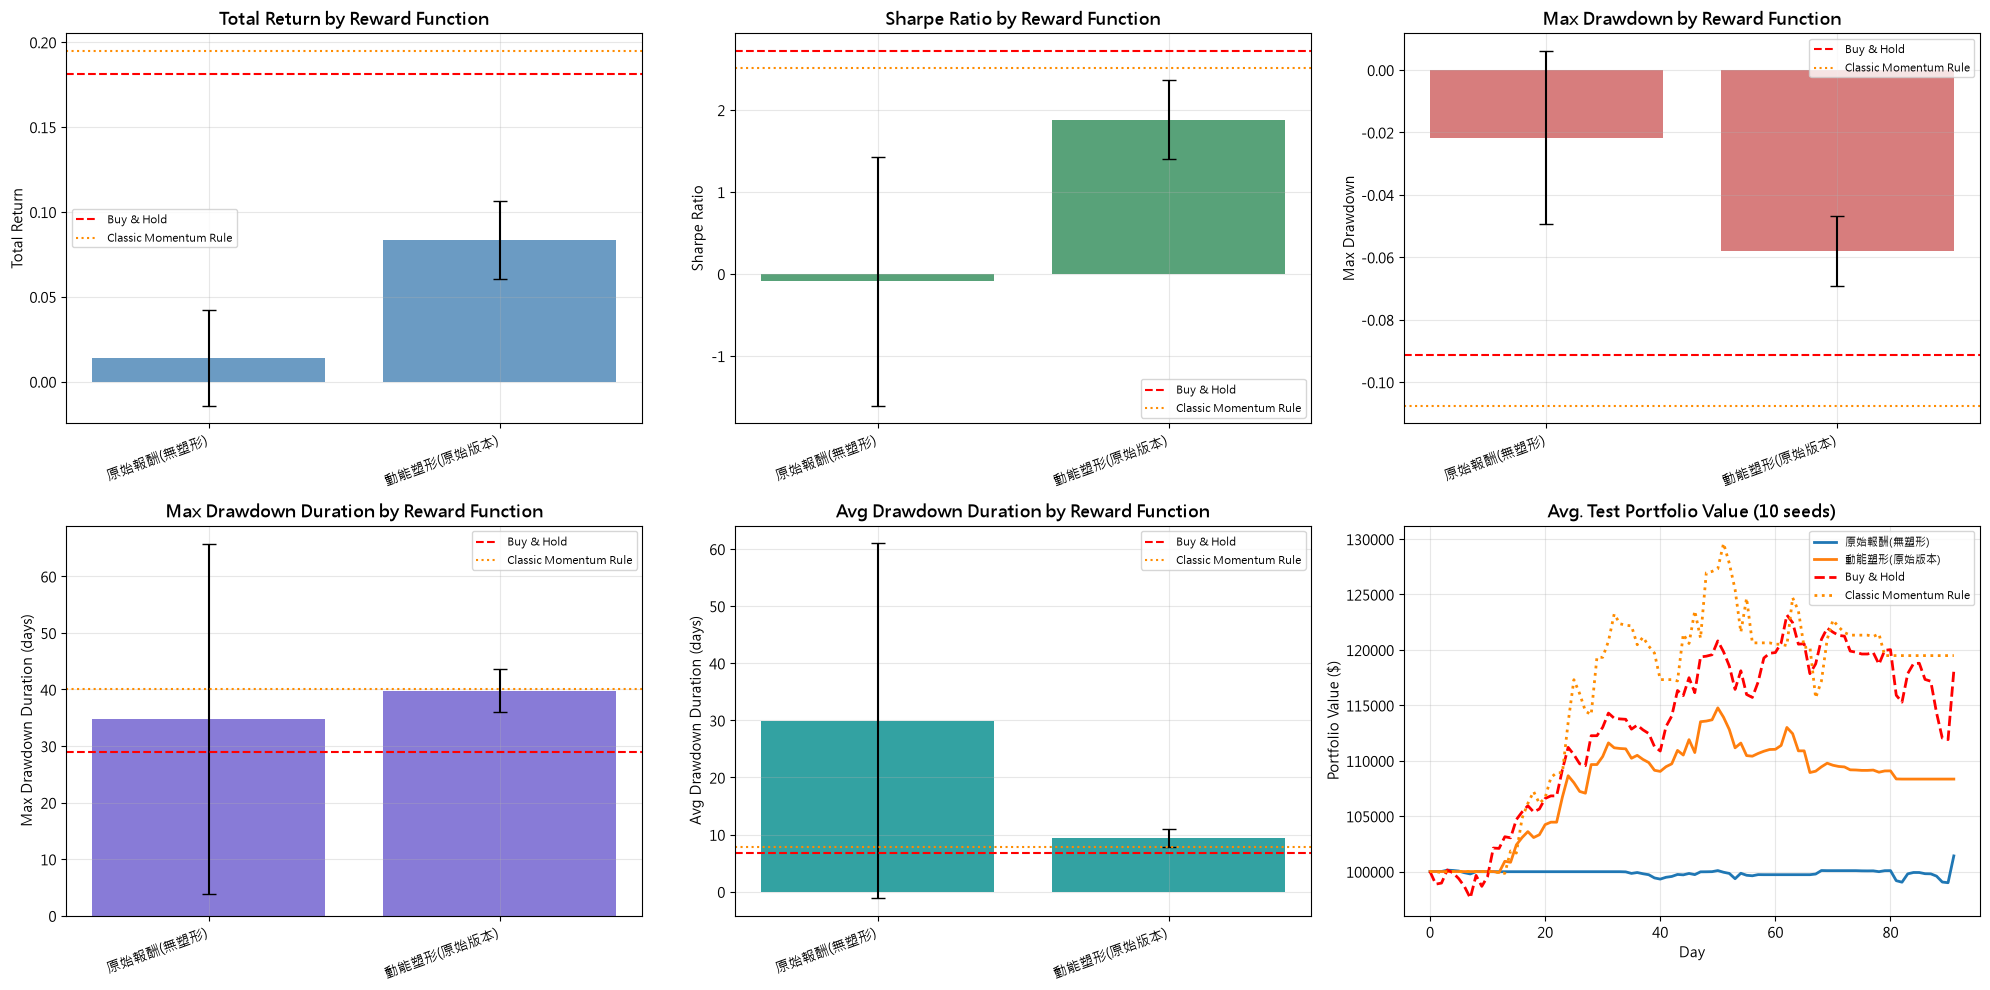


獎勵函數比較圖表已顯示！


In [17]:
mode_labels = [REWARD_MODES[m] for m in REWARD_MODES]
x = np.arange(len(REWARD_MODES))

fig, axes = plt.subplots(2, 3, figsize=(20, 10))


def plot_bar_with_refs(ax, metric, title, color):
    means = [summary.loc[m, (metric, 'mean')] for m in REWARD_MODES]
    stds = [summary.loc[m, (metric, 'std')] for m in REWARD_MODES]
    ax.bar(x, means, yerr=stds, capsize=5, alpha=0.8, color=color)
    ax.axhline(y=buy_hold_metrics[metric], color='red', linestyle='--', label='Buy & Hold')
    ax.axhline(y=classic_momentum_metrics[metric], color='darkorange', linestyle=':', label='Classic Momentum Rule')
    ax.set_xticks(x)
    ax.set_xticklabels(mode_labels, rotation=20, ha='right')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)


# 總報酬長條圖（含誤差棒）
plot_bar_with_refs(axes[0, 0], 'total_return', 'Total Return by Reward Function', 'steelblue')
axes[0, 0].set_ylabel('Total Return')

# 夏普比長條圖
plot_bar_with_refs(axes[0, 1], 'sharpe_ratio', 'Sharpe Ratio by Reward Function', 'seagreen')
axes[0, 1].set_ylabel('Sharpe Ratio')

# 最大回撤長條圖
plot_bar_with_refs(axes[0, 2], 'max_drawdown', 'Max Drawdown by Reward Function', 'indianred')
axes[0, 2].set_ylabel('Max Drawdown')

# 最大回撤持續期間長條圖
plot_bar_with_refs(axes[1, 0], 'max_drawdown_duration', 'Max Drawdown Duration by Reward Function', 'slateblue')
axes[1, 0].set_ylabel('Max Drawdown Duration (days)')
axes[1, 0].set_xlabel('')

# 平均回撤持續期間長條圖
plot_bar_with_refs(axes[1, 1], 'avg_drawdown_duration', 'Avg Drawdown Duration by Reward Function', 'darkcyan')
axes[1, 1].set_ylabel('Avg Drawdown Duration (days)')
axes[1, 1].set_xlabel('')

# 測試集平均投資組合曲線
ax = axes[1, 2]
for reward_mode in REWARD_MODES:
    histories = [m['portfolio_history'] for m in reward_comparison_results if m['reward_mode'] == reward_mode]
    min_len = min(len(h) for h in histories)
    avg_history = np.mean([h[:min_len] for h in histories], axis=0)
    ax.plot(avg_history, label=REWARD_MODES[reward_mode], linewidth=2)
ax.plot(buy_hold_portfolio, label='Buy & Hold', linewidth=2, color='red', linestyle='--')
ax.plot(classic_momentum_portfolio, label='Classic Momentum Rule', linewidth=2, color='darkorange', linestyle=':')
ax.set_title('Avg. Test Portfolio Value (10 seeds)', fontweight='bold')
ax.set_xlabel('Day')
ax.set_ylabel('Portfolio Value ($)')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n獎勵函數比較圖表已顯示！")